# Natural policy gradient on a Gaussian bandit

A bandit is the simplest case of the algorithm of Steps 20–21 of the notes (after Kakade, 2001): one state, so the state distribution is trivial and $F_p=F_s$.
Everything below is driven by the variables in the **configuration cell**: the number and the means of the arms, the reward variance, the starting policy, the batch size, the
hyperparameter grids and so on. Change them there and *Run All*. The text refers to these variables by name and never to their values; the numbers are printed by the code cells.

**The setting.** Arm $a\in\{0,\dots,K-1\}$ (with $K$ the number of arms) pays a Gaussian reward with mean $\mu_a$ and variance $\sigma_a^2$ (`REWARD_VARIANCE`).
A policy is a probability vector $\pi=(\pi_a)$ with all $\pi_a>0$, and the objective is $\eta(\pi)=\sum_a\pi_a\mu_a$. The reward noise does not change $\eta$; it only makes the gradient estimates noisy.

**How it connects to the notes.**

| Notes | Here |
|---|---|
| $M$, the manifold of policies | the open simplex $\{\pi:\pi_a>0,\ \sum_a\pi_a=1\}$, of dimension $K-1$ |
| chart $\theta$ | $\theta_a=\log\pi_a-\log\pi_{\rm ref}$ for $a\ne{\rm ref}$ (Section 1) |
| $\eta$, a function on $M$ | expected reward $\sum_a\pi_a\mu_a$ |
| $(d\ell_a)_p$, the score | covector with components $\delta_{ab}-\pi_b$ |
| $F_p$ | Fisher metric, $\operatorname{diag}(\pi_{\rm free})-\pi_{\rm free}\pi_{\rm free}^\top$ in the chart |
| $\operatorname{grad}_F\eta$ | natural gradient, with components $\mu_a-\mu_{\rm ref}$ |

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True, linewidth=140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# =========================================================================================
#                         CONFIGURATION: edit here, then "Run All"
# =========================================================================================
# ---- the arms ------------------------------------------------------------------------
ARMS_MODE       = "manual"             # "manual": use MEANS_MANUAL;  "random": draw N_ARMS means uniformly in MEAN_RANGE
MEANS_MANUAL    = [2.0, 5.0, 8.0]      # used when ARMS_MODE == "manual"
N_ARMS          = 3                    # used when ARMS_MODE == "random"
MEAN_RANGE      = (0.0, 10.0)          # used when ARMS_MODE == "random"
MEANS_SEED      = 0                    # seed for the random means
REWARD_VARIANCE = 2.0                  # variance of the Gaussian reward (a list gives one variance per arm)

# ---- the policy: chart and starting point --------------------------------------------
REF_ARM         = -1                   # arm whose logit is fixed to 0 (this makes theta a genuine chart); -1 = last arm
INIT_MODE       = "manual"             # "uniform" | "best_arm_prob" | "manual"
BEST_ARM_INIT_PROB = 0.02              # "best_arm_prob": the best arm starts with this probability, the others share the rest equally
INIT_PROBS      = [0.90, 0.08, 0.02]   # "manual": one probability per arm (must be > 0 and sum to 1)

# ---- sampling ------------------------------------------------------------------------
BATCH_SIZE      = 100                  # arm pulls per policy update
BASELINE        = "leave_one_out"      # "leave_one_out" (mean of the other rewards) | "exact" (true expected return) | "none"

# ---- optimisation experiments --------------------------------------------------------
N_ITERS         = 60                   # policy updates per sampled run
N_ITERS_EXACT   = 100                  # policy updates per noise-free (exact-gradient) run
N_SEEDS         = 40                   # independent sampled runs per setting
LR_GRID         = [0.1, 0.5, 2.0, 8.0, 30.0]        # vanilla learning rates to try
EPS_GRID        = [0.01, 0.03, 0.1, 0.3]            # natural-gradient KL budgets to try
INCLUDE_UNDAMPED = True                # also run natural gradient with DAMPING = 0, to see the failure mode
DAMPING_SCALE   = 0.03                 # damping lambda = DAMPING_SCALE / (number of arms) ...
DAMPING         = None                 # ... unless you set lambda directly here (a number)
MAX_LOGIT_STEP  = 10.0                 # no update may change any coordinate theta_a by more than this (None = no cap)
SKIP_RELATIVE_Q = 1e-12                # skip an update when q < this * mean(A_hat^2): the batch carries no information
SUCCESS_FRAC    = 0.95                 # "solved" = reaching eta_init + SUCCESS_FRAC * (eta_star - eta_init)
TRACE_ITERS     = 12                   # iterations printed in the failure trace
N_REF_TESTED    = 6                    # Experiment E: number of different reference arms tried (all arms if K is smaller)

# ---- checks and tests ----------------------------------------------------------------
CHECK_BATCH     = 200_000              # one big batch to compare sampled estimators with exact values
KL_CHECK_LOG10_EPS = (-4.0, 0.5)       # range of log10(epsilon) for the quadratic-KL check
CHART_SCALE_SPREAD = 3.0               # chart test: coordinates rescaled by factors in [1/spread, spread]
SENS_CHART_SCALE   = 3.0               # sensitivity test: uniform rescaling theta' = c * theta
SENS_ITERS      = 30                   # updates per run in the sensitivity test
SENS_SEEDS      = 20                   # runs per point
SENS_POINTS     = 13                   # grid points per hyperparameter
SENS_LR_LOG10   = (-1.5, 2.5)          # log10 range of the vanilla learning rate
SENS_EPS_LOG10  = (-3.0, 0.0)          # log10 range of the KL budget

def hp_label(m):
    """Plot label of the hyperparameter of a method: alpha (learning rate) for vanilla, epsilon (KL budget) for natural."""
    return r"$\alpha$" if m in ("vanilla", "lr") else r"$\varepsilon$"

## 1. The bandit, and the chart

**The chart must be a bijection.** The map "policy $\mapsto$ all $K$ softmax logits" is *not* a chart in the sense of Step 2 of the notes: adding the same constant to every logit leaves $\pi$ unchanged,
so it is not injective, the parameter space has one dimension too many, and the Fisher matrix in those coordinates has a kernel ($\mathbf 1$).

Fix a reference arm $\text{ref}$ (`REF_ARM`) and use the $K-1$ coordinates
$$\theta_a=\log\pi_a-\log\pi_{\rm ref}\quad(a\ne{\rm ref}),\qquad \theta^{-1}:\ \pi_a=\frac{e^{\theta_a}}{1+\sum_{b\ne{\rm ref}}e^{\theta_b}},\quad \pi_{\rm ref}=\frac{1}{1+\sum_{b\ne{\rm ref}}e^{\theta_b}}.$$
This is a bijection between $M$ and $\mathbb R^{K-1}$, so $\dim M=K-1$ equals the number of coordinates, and $F$ will be positive definite.

The cell below builds the arms (explicitly from `MEANS_MANUAL`, or drawn at random with `N_ARMS`, `MEAN_RANGE`, `MEANS_SEED`), the reference arm, the starting policy (`INIT_MODE`), and plots both.
The initial policy is where the plateau experiments live: `INIT_MODE = "best_arm_prob"` gives the best arm the probability `BEST_ARM_INIT_PROB`, `"uniform"` starts from equal probabilities, `"manual"` uses `INIT_PROBS`.

3 arms, reward std = [1.414 1.414 1.414], best arm = 2 (mean 8.000), reference arm = 2
means: [2. 5. 8.]
initial policy: [0.9  0.08 0.02]
eta_init = 2.360, eta* = 8.000, success target = 7.718 (95% of the gap)
manifold dimension K-1 = 2;  damping lambda = 0.01;  batch size = 100


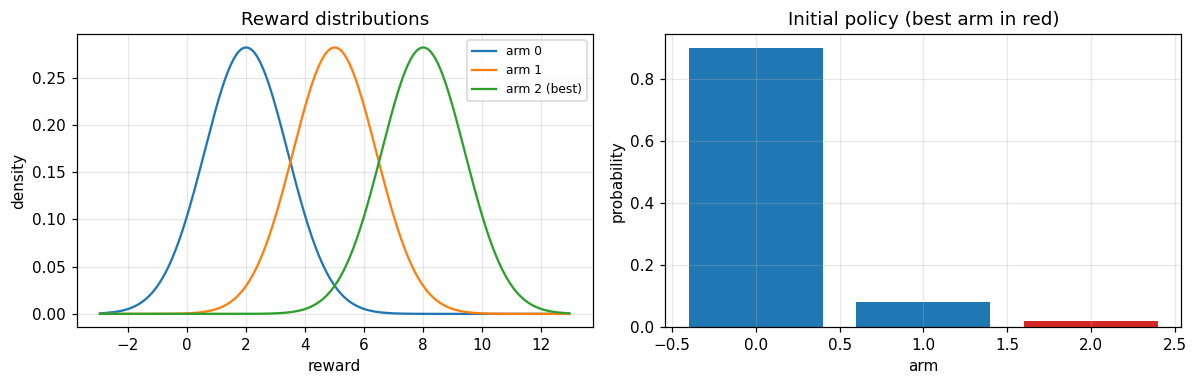

In [2]:
def make_arms():
    if ARMS_MODE == "manual":
        means = np.array(MEANS_MANUAL, dtype=float)
    else:
        means = np.random.default_rng(MEANS_SEED).uniform(MEAN_RANGE[0], MEAN_RANGE[1], N_ARMS)
    variances = np.broadcast_to(np.asarray(REWARD_VARIANCE, dtype=float), means.shape).copy()
    return means, variances

MEANS, VARIANCES = make_arms()
STDS = np.sqrt(VARIANCES)
K = len(MEANS)                                   # number of arms
assert K >= 2, "need at least two arms"
BEST = int(np.argmax(MEANS))                     # index of the best arm
REF = REF_ARM % K                                # reference arm (its logit is fixed to 0)
OTHER = [a for a in range(K) if a != REF]        # arms whose coordinate theta_a is a free parameter
OTHER_ARR = np.array(OTHER)
N_FREE = K - 1                                   # dimension of the manifold M (the open simplex)
LAMBDA = DAMPING_SCALE / K if DAMPING is None else float(DAMPING)    # damping used by sampled natural gradient

def make_init_probs():
    if INIT_MODE == "uniform":
        p = np.ones(K) / K
    elif INIT_MODE == "best_arm_prob":
        p = np.full(K, (1.0 - BEST_ARM_INIT_PROB) / (K - 1)); p[BEST] = BEST_ARM_INIT_PROB
    elif INIT_MODE == "manual":
        p = np.array(INIT_PROBS, dtype=float)
        assert len(p) == K, f"INIT_PROBS has {len(p)} entries but there are {K} arms"
        assert np.all(p > 0) and abs(p.sum() - 1) < 1e-9, "INIT_PROBS must be positive and sum to 1"
    else:
        raise ValueError(INIT_MODE)
    return p

PI_INIT = make_init_probs()

# ---------------- the chart: theta_a = log pi_a - log pi_REF, for the K-1 arms a != REF ----------------
def softmax(z):
    e = np.exp(z - z.max()); return e / e.sum()

def pi_from_theta(theta):                     # theta^{-1}: coordinates -> policy
    z = np.zeros(K); z[OTHER] = theta; return softmax(z)

def theta_from_pi(pi):                        # theta: policy -> coordinates
    return np.log(pi[OTHER]) - np.log(pi[REF])

THETA_INIT = theta_from_pi(PI_INIT)

def kl(p, q):                                 # KL(p || q): p = old policy, q = new policy
    return float(np.sum(p * np.log(p / q)))

# ---------------- exact objects ----------------
def eta_of(pi):      return float(pi @ MEANS)                     # expected return, a function on M
def exact_adv(pi):   return MEANS - eta_of(pi)                    # A(a) = mu_a - eta
def exact_grad(pi):  return (pi * exact_adv(pi))[OTHER]           # components of d(eta) in the chart theta
def fisher(pi):
    p = pi[OTHER]; return np.diag(p) - np.outer(p, p)             # F in the chart theta (K-1 x K-1)
def exact_natural(pi):
    return MEANS[OTHER] - MEANS[REF]                              # w_a = A_a - A_ref = mu_a - mu_ref (closed form of F^{-1} g)
def fisher_quad(pi, w):
    p = pi[OTHER]; return float(p @ w**2 - (p @ w) ** 2)          # F(w, w) = Var_{a~pi}[w_a], with w_REF = 0

ETA_INIT = eta_of(PI_INIT)
ETA_STAR = float(MEANS.max())
TARGET = ETA_INIT + SUCCESS_FRAC * (ETA_STAR - ETA_INIT)

print(f"{K} arms, reward std = {np.round(STDS, 3)}, best arm = {BEST} (mean {MEANS[BEST]:.3f}), reference arm = {REF}")
print(f"means: {np.round(MEANS, 3) if K <= 12 else str(np.round(np.sort(MEANS)[::-1][:5], 3)) + ' ... (top 5 shown)'}")
print(f"initial policy: {np.round(PI_INIT, 4) if K <= 12 else 'best arm has probability %.4f' % PI_INIT[BEST]}")
print(f"eta_init = {ETA_INIT:.3f}, eta* = {ETA_STAR:.3f}, success target = {TARGET:.3f} ({SUCCESS_FRAC:.0%} of the gap)")
print(f"manifold dimension K-1 = {N_FREE};  damping lambda = {LAMBDA:.3g};  batch size = {BATCH_SIZE}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
if K <= 10:
    xs = np.linspace(MEANS.min() - 3.5 * STDS.max(), MEANS.max() + 3.5 * STDS.max(), 400)
    for a in range(K):
        pdf = np.exp(-0.5 * ((xs - MEANS[a]) / STDS[a]) ** 2) / (STDS[a] * np.sqrt(2 * np.pi))
        axes[0].plot(xs, pdf, label=f"arm {a}" + (" (best)" if a == BEST else ""))
    axes[0].set_xlabel("reward"); axes[0].set_ylabel("density"); axes[0].legend(fontsize=8)
else:
    order = np.argsort(MEANS)[::-1]
    axes[0].errorbar(np.arange(K), MEANS[order], yerr=STDS[order], fmt="o", ms=3, lw=0.8)
    axes[0].set_xlabel("arm (sorted by mean)"); axes[0].set_ylabel("mean reward +- std")
axes[0].set_title("Reward distributions")
colors = ["C3" if a == BEST else "C0" for a in range(K)]
axes[1].bar(np.arange(K), PI_INIT, color=colors); axes[1].set_xlabel("arm"); axes[1].set_ylabel("probability")
axes[1].set_title("Initial policy (best arm in red)")
plt.tight_layout(); plt.show()

## 2. Exact objects (the means are known), our ground truth

**Advantage:** $A_a=\mu_a-\eta$, and $\sum_a\pi_aA_a=0$.

**Score.** $\ell_a=\log\pi_a$ has $\dfrac{\partial\ell_a}{\partial\theta_b}=\delta_{ab}-\pi_b$ for the free coordinates $b\neq{\rm ref}$ (and for $a={\rm ref}$ it is $-\pi_b$).
These are the components of the covector $(d\ell_a)_p$ in the dual basis $d\theta^b$ (Steps 7–8).

**Differential of $\eta$** (policy gradient theorem; Step 8 and the REINFORCE remark):
$$\frac{\partial\eta}{\partial\theta_b}=\sum_a\pi_aA_a(\delta_{ab}-\pi_b)=\pi_b\,A_b,\qquad b\ne{\rm ref}.$$
The factor $\pi_b$ is what makes vanilla ascent slow when the best arm is rarely played.

**Fisher metric** (Step 18), $F=\mathbb E_{a\sim\pi}[\phi\phi^\top]$ with $\phi_b=\delta_{ab}-\pi_b$:
$$F=\operatorname{diag}(\pi_{\rm free})-\pi_{\rm free}\pi_{\rm free}^\top,\qquad F(w,w)=\operatorname{Var}_{a\sim\pi}[w_a]\ \ \text{with } w_{\rm ref}:=0 .$$
It is positive definite: $F(w,w)=0$ would force $w_a$ to be the same for all arms, including the reference arm where $w_{\rm ref}=0$, hence $w=0$.

**Natural gradient.** Solve $Fw=g$ with $g_b=\pi_bA_b$. Since $\sum_a\pi_aw_a=\sum_a\pi_a(A_a-A_{\rm ref})=-A_{\rm ref}$, the vector $w_b=A_b-A_{\rm ref}=\mu_b-\mu_{\rm ref}$ satisfies
$(Fw)_b=\pi_b(w_b-\pi\cdot w)=\pi_bA_b$. So in this chart
$$\operatorname{grad}_F\eta\ \text{has components}\ \ w_b=\mu_b-\mu_{\rm ref}\qquad(b\ne{\rm ref}):$$
the $\pi_b$ factors of the gradient are cancelled by $F^{-1}$, and the direction does not depend on the current policy at all.
(In a redundant chart the same vector is "$A_a$ up to an additive constant", which is why the old formulation needed a pseudoinverse.)

The checks below verify these formulas numerically on a random policy.

In [3]:
# ---- checks on a random strictly positive policy ----
rng_chk = np.random.default_rng(1)
th_chk = rng_chk.normal(size=N_FREE); pi_chk = pi_from_theta(th_chk)
g_chk = exact_grad(pi_chk)
g_num = np.zeros(N_FREE)
for j in range(N_FREE):
    dl = np.zeros(N_FREE); dl[j] = 1e-6
    g_num[j] = (eta_of(pi_from_theta(th_chk + dl)) - eta_of(pi_from_theta(th_chk - dl))) / 2e-6
print("exact gradient vs finite differences, max abs error:", np.abs(g_chk - g_num).max())

F_chk = fisher(pi_chk)
print(f"Fisher matrix {F_chk.shape}: smallest eigenvalue = {np.linalg.eigvalsh(F_chk).min():.3e}  (> 0: positive definite, no kernel)")
w_solve = np.linalg.solve(F_chk, g_chk)
print("natural gradient: linear solve F^{-1} g  vs  closed form mu_a - mu_ref, max abs diff:",
      np.abs(w_solve - exact_natural(pi_chk)).max())

# ---- the same objects at the initial policy ----
print("\nat the initial policy:")
print("  d(eta) components (vanilla direction) :", exact_grad(PI_INIT) if K <= 12 else "(K large, not printed)")
print("  natural direction  mu_a - mu_ref      :", exact_natural(PI_INIT) if K <= 12 else "(K large, not printed)")

exact gradient vs finite differences, max abs error: 2.5046176244103435e-10
Fisher matrix (2, 2): smallest eigenvalue = 8.261e-02  (> 0: positive definite, no kernel)
natural gradient: linear solve F^{-1} g  vs  closed form mu_a - mu_ref, max abs diff: 8.881784197001252e-16

at the initial policy:
  d(eta) components (vanilla direction) : [-0.324   0.2112]
  natural direction  mu_a - mu_ref      : [-6. -3.]


## 3. The KL budget: does $\tfrac12F(\delta,\delta)$ measure KL?

The step size of the algorithm is chosen so that a displacement $\delta=\alpha w$ has $\mathrm{KL}(\pi_{\rm old}\,\|\,\pi_{\rm new})\approx\tfrac12F(\delta,\delta)=\varepsilon$, i.e. $\alpha=\sqrt{2\varepsilon/F(w,w)}$.
This is a **second-order Taylor expansion** of KL at its minimum (Steps 16–18), so it must be accurate for small $\varepsilon$ and degrade for large $\varepsilon$.
We test it with the exact natural direction, for $\log_{10}\varepsilon$ in `KL_CHECK_LOG10_EPS`, by taking the step $\theta^{-1}(\theta(p)+\alpha w)$ and measuring the true KL.

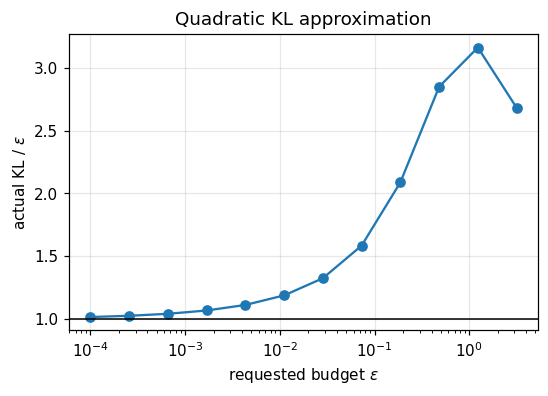

In [4]:
w0 = exact_natural(PI_INIT)
eps_grid = np.logspace(KL_CHECK_LOG10_EPS[0], KL_CHECK_LOG10_EPS[1], 12)
ratio = []
for eps in eps_grid:
    alpha = np.sqrt(2 * eps / fisher_quad(PI_INIT, w0))               # step from the KL budget
    pi_new = pi_from_theta(THETA_INIT + alpha * w0)                  # Step_theta(p, v) = theta^{-1}(theta(p) + alpha w)
    ratio.append(kl(PI_INIT, pi_new) / eps)                          # actual KL / requested KL
plt.figure(figsize=(5.5, 3.5))
plt.semilogx(eps_grid, ratio, "o-"); plt.axhline(1.0, color="k", lw=1)
plt.xlabel(r"requested budget $\varepsilon$"); plt.ylabel(r"actual KL $/\ \varepsilon$"); plt.title("Quadratic KL approximation")
plt.show()

The ratio tends to 1 as $\varepsilon\to0$. For large $\varepsilon$ the true KL differs from the requested one, so the budget is only a *local* statement.

## 4. The algorithm (Steps 1–5)

Everything below is shared by the experiments. Each iteration draws a batch of `BATCH_SIZE` pulls $(a_i,r_i)$ with $a_i\sim\pi$, and then:

1. **Features.** Row $i$ of $\Phi$ is $\phi_i^\top$, the components in the chart $\theta$ of the covector $(d\ell_{a_i})_p$: $[a_i=b]-\pi_b$ for $b\neq{\rm ref}$.
2. **Advantages.** $\hat A_i=r_i-b_i$ with a baseline $b_i$ that does not depend on $a_i$ (`BASELINE`). The default is the mean of the *other* rewards in the batch (leave-one-out), which keeps the estimate unbiased;
   `"exact"` subtracts $\eta(\pi)$, `"none"` subtracts nothing. A baseline that depended on the action would not be orthogonal to the span of the score features (Remark in Step 20) and would bias the result.
3. **Vanilla direction.** $\hat g=\frac1N\sum_i\hat A_i\phi_i$, an estimate of the components of $d\eta$. Update: $\theta\leftarrow\theta+\text{lr}\,\hat g$.
4. **Natural direction (regression).** Fit $\hat A_i\approx w^\top\phi_i$ by least squares. The normal equations are $(\hat F+\lambda\Lambda)w=\hat g$ with $\hat F=\frac1N\sum_i\phi_i\phi_i^\top$, where
   $\lambda$ is the damping (`DAMPING`, or `DAMPING_SCALE`$/K$ by default) and $\Lambda=D^{-2}$ in a chart $\psi=D\theta$ ($\Lambda=I$ in the chart $\theta$).
   The damping is there because $\hat F$ only contains information on the arms that were actually sampled (see Experiment B); $\lambda=0$ gives the plain regression.
5. **KL budget.** $\alpha=\sqrt{2\varepsilon/q}$ with $q=w^\top(\hat F+\lambda\Lambda)w$, then $\theta\leftarrow\theta+\alpha w$.

**Uninformative batches.** The step $\alpha=\sqrt{2\varepsilon/q}$ divides by the information $q$ in the batch. If the batch contains no information (for instance every pull falls on the same arm, so $\hat g=0$ up to round-off), this normalisation inflates round-off noise to a full-size step in a random direction, and the result even depends on the chart. The update is skipped when $q\le$ `SKIP_RELATIVE_Q` $\cdot\,\overline{\hat A^2}$.

`MAX_LOGIT_STEP` caps the largest change of any coordinate in one update (for both methods). It is a numerical safeguard: near a deterministic policy $q\to0$ and the KL-budget step explodes.
We use a cap rather than clipping the coordinates, because in this chart (reference logit pinned to 0) clipping can force two near-equal best arms to tie. The cap is measured in the coordinates of the chart: invariant under rescalings of the coordinates, but not under a change of reference arm (see Experiment E).

In [5]:
def cap_step(step, scales):
    """Rescale an update so that no coordinate theta changes by more than MAX_LOGIT_STEP (direction unchanged)."""
    if MAX_LOGIT_STEP is None: return step
    m = np.max(np.abs(step / scales))
    return step if m <= MAX_LOGIT_STEP else step * (MAX_LOGIT_STEP / m)

def first_hit(curve, level):
    hit = np.flatnonzero(curve >= level)
    return int(hit[0]) if len(hit) else None

# ------------------------------- noise-free optimisation -------------------------------
def run_exact(method, n_iter, lr=None, eps=None, scales=None):
    """Exact gradient / exact natural direction at every iteration.
    scales: positive vector; the chart is psi = scales * theta (another parametrisation of the same policies)."""
    scales = np.ones(N_FREE) if scales is None else scales
    psi = THETA_INIT * scales; etas = []
    for k in range(n_iter):
        pi = pi_from_theta(psi / scales); etas.append(eta_of(pi))
        if method == "vanilla":
            step = lr * (exact_grad(pi) / scales)                            # components of the covector d(eta) in the chart psi
        else:
            w = exact_natural(pi)
            step = np.sqrt(2 * eps / max(fisher_quad(pi, w), 1e-300)) * (w * scales)   # components of the vector v_* in psi
        psi = psi + cap_step(step, scales)
    etas.append(eta_of(pi_from_theta(psi / scales)))
    return np.array(etas)

# ------------------------------- sampling -------------------------------
def sample_batch(pi, N, rng):
    actions = rng.choice(K, size=N, p=pi)                                    # always from the CURRENT policy
    rewards = MEANS[actions] + STDS[actions] * rng.standard_normal(N)
    return actions, rewards

def features(pi, actions):
    """Row i = components in the chart theta of the covector (d ell_{a_i}):  [a_i == a'] - pi_{a'}  for a' != REF."""
    return (actions[:, None] == OTHER_ARR[None, :]).astype(float) - pi[OTHER][None, :]

def advantage_estimates(pi, rewards):
    N = len(rewards)
    if BASELINE == "leave_one_out": b = (rewards.sum() - rewards) / (N - 1)   # independent of a_i, so unbiased
    elif BASELINE == "exact":       b = eta_of(pi)
    elif BASELINE == "none":        b = 0.0
    else: raise ValueError(BASELINE)
    return rewards - b

def sampled_directions(pi, N, rng, scales=None, lam=None):
    """One batch -> (vanilla gradient estimate g_hat, natural direction w, quadratic form q, actions)."""
    scales = np.ones(N_FREE) if scales is None else scales
    lam = LAMBDA if lam is None else lam
    actions, rewards = sample_batch(pi, N, rng)
    Phi = features(pi, actions) / scales                  # features in the chart psi = scales * theta
    A_hat = advantage_estimates(pi, rewards)
    g_hat = Phi.T @ A_hat / N                             # estimate of d(eta)
    F_hat = Phi.T @ Phi / N                               # estimate of the Fisher metric
    Lam = lam / scales**2                                 # covariant damping: lam * I in the chart theta
    if lam > 0:
        w = np.linalg.solve(F_hat + np.diag(Lam), g_hat)  # (F_hat + lam Lambda) w = g_hat
    else:
        w = np.linalg.lstsq(Phi, A_hat, rcond=None)[0]    # plain regression (minimum-norm solution if rank-deficient)
    q = float(w @ F_hat @ w + w @ (Lam * w))
    if q <= SKIP_RELATIVE_Q * float(np.mean(A_hat ** 2)):
        # Uninformative batch (e.g. every pull on the same arm): g_hat is zero up to round-off, and the step
        # alpha = sqrt(2 eps / q) would blow that round-off up to a full-size step in a random direction. Skip the update.
        return np.zeros_like(g_hat), np.zeros_like(w), 1.0, actions
    return g_hat, w, q, actions

def run_sampled(method, n_iter, seed, lr=None, eps=None, scales=None, lam=None, N=None, trace=False):
    scales = np.ones(N_FREE) if scales is None else scales
    N = BATCH_SIZE if N is None else N
    rng = np.random.default_rng(seed); psi = THETA_INIT * scales; etas = []; log = []
    for k in range(n_iter):
        pi = pi_from_theta(psi / scales); etas.append(eta_of(pi))
        g_hat, w, q, actions = sampled_directions(pi, N, rng, scales, lam)
        if method == "vanilla":
            step = lr * g_hat; alpha = lr
        else:
            alpha = np.sqrt(2 * eps / max(q, 1e-300)); step = alpha * w
        if trace: log.append((k, pi.copy(), int(K - len(np.unique(actions))), float(np.abs(w / scales).max()), float(alpha), etas[-1]))
        psi = psi + cap_step(step, scales)
    pi_final = pi_from_theta(psi / scales); etas.append(eta_of(pi_final))
    return (np.array(etas), pi_final, log) if trace else (np.array(etas), pi_final)

# ------------------------------- changing the reference arm (a different chart for the same problem) -------------------------------
from contextlib import contextmanager

@contextmanager
def with_reference(ref):
    """Temporarily use arm `ref` as the reference arm (logit fixed to 0): same policies, a different chart."""
    global REF, OTHER, OTHER_ARR, THETA_INIT
    saved = (REF, OTHER, OTHER_ARR, THETA_INIT)
    REF = ref; OTHER = [a for a in range(K) if a != ref]; OTHER_ARR = np.array(OTHER); THETA_INIT = theta_from_pi(PI_INIT)
    try: yield
    finally: REF, OTHER, OTHER_ARR, THETA_INIT = saved

def reference_arms():
    if K <= N_REF_TESTED: return list(range(K))
    worst = int(np.argmin(MEANS)); rng = np.random.default_rng(MEANS_SEED)
    rest = [a for a in range(K) if a not in (BEST, worst)]
    return [BEST, worst] + sorted(int(a) for a in rng.choice(rest, N_REF_TESTED - 2, replace=False))

In [6]:
# Compare the sampled estimators with the exact values at the initial policy, using one big batch (CHECK_BATCH pulls).
rng = np.random.default_rng(0)
g_hat, w_hat, q_hat, _ = sampled_directions(PI_INIT, CHECK_BATCH, rng, lam=0.0)
g_ex, w_ex = exact_grad(PI_INIT), exact_natural(PI_INIT)
cosine = lambda a, b: float(a @ b / np.linalg.norm(a) / np.linalg.norm(b))
print(f"batch of {CHECK_BATCH} pulls")
print(f"cosine(sampled vanilla direction, exact d(eta))        = {cosine(g_hat, g_ex):.4f}")
print(f"cosine(sampled natural direction, exact natural dir.)  = {cosine(w_hat, w_ex):.4f}")
if K <= 12:
    print("vanilla  sampled:", g_hat, "  exact:", g_ex)
    print("natural  sampled:", w_hat, "  exact:", w_ex)

batch of 200000 pulls
cosine(sampled vanilla direction, exact d(eta))        = 1.0000
cosine(sampled natural direction, exact natural dir.)  = 1.0000
vanilla  sampled: [-0.3207  0.2071]   exact: [-0.324   0.2112]
natural  sampled: [-6.0006 -3.0097]   exact: [-6. -3.]


## 5. Experiment A: noise-free comparison (exact gradients)

First remove all sampling noise: at each iteration use the exact $d\eta$ and the exact $\operatorname{grad}_F\eta$. This isolates the *geometry* of the two update rules.
Reference levels in the plot: $\eta^*=\max_a\mu_a$ (solid), the starting value (dotted) and the success target, at fraction `SUCCESS_FRAC` of the gap (dashed).

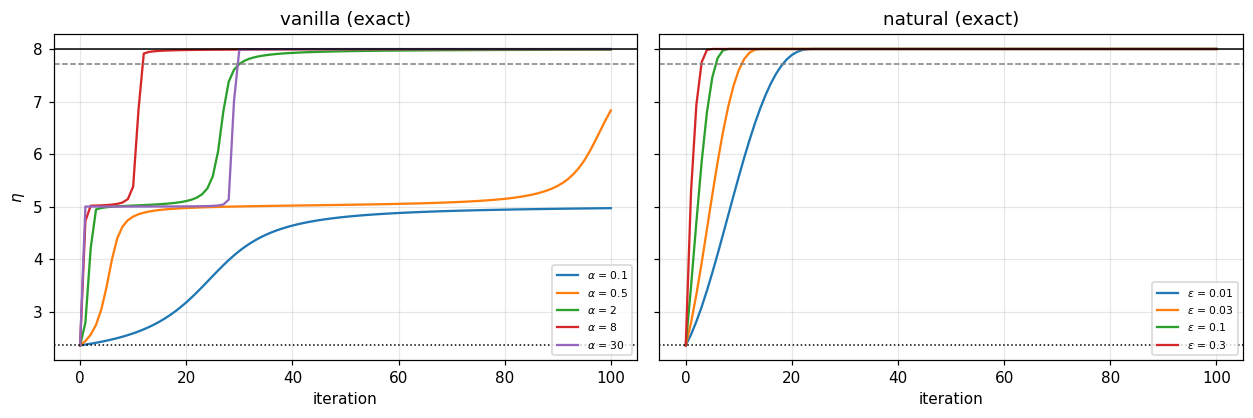

method      setting  final eta  gap closed   iterations to reach 50%  90%  95%  99%
vanilla      lr=0.1      4.971       46.3%       -      -      -      -
vanilla      lr=0.5      6.830       79.3%      83      -      -      -
vanilla        lr=2      7.986       99.8%      23     29     31     45
vanilla        lr=8      7.997      100.0%      10     12     12     13
vanilla       lr=30      7.999      100.0%      29     30     30     30
natural    eps=0.01      8.000      100.0%       9     17     19     21
natural    eps=0.03      8.000      100.0%       5     10     11     13
natural     eps=0.1      8.000      100.0%       3      5      6      7
natural     eps=0.3      8.000      100.0%       1      3      3      4


In [7]:
FRACS = sorted(set([0.5, 0.9, SUCCESS_FRAC, 0.99]))
def level(f): return ETA_INIT + f * (ETA_STAR - ETA_INIT)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), sharey=True)
exact_rows = []
for ax, method, grid, name in [(axes[0], "vanilla", LR_GRID, "lr"), (axes[1], "natural", EPS_GRID, "eps")]:
    for hp in grid:
        curve = run_exact(method, N_ITERS_EXACT, **{name: hp})
        ax.plot(curve, label=f"{hp_label(name)} = {hp:g}"); exact_rows.append((method, f"{name}={hp:g}", curve))
    ax.axhline(ETA_STAR, color="k", lw=1); ax.axhline(ETA_INIT, color="k", lw=1, ls=":"); ax.axhline(TARGET, color="gray", lw=1, ls="--")
    ax.set_title(f"{method} (exact)"); ax.set_xlabel("iteration"); ax.legend(fontsize=7, loc="lower right")
axes[0].set_ylabel(r"$\eta$"); plt.tight_layout(); plt.show()

print(f"{'method':8s} {'setting':>10s} {'final eta':>10s} {'gap closed':>11s}   iterations to reach " + "  ".join(f"{f:.0%}" for f in FRACS))
for method, setting, curve in exact_rows:
    hits = [first_hit(curve, level(f)) for f in FRACS]
    print(f"{method:8s} {setting:>10s} {curve[-1]:10.3f} {(curve[-1]-ETA_INIT)/(ETA_STAR-ETA_INIT):11.1%}   "
          + "  ".join(f"{('-' if h is None else h):>5}" for h in hits))

**Reading the table.** "-" means the level was not reached within `N_ITERS_EXACT` iterations. Look at how the iteration counts change with the setting, and at whether a large learning rate
makes vanilla ascent commit to an arm that is not the best one. The vanilla gradient component is $\pi_bA_b$, so its progress depends on how much probability the arms currently have;
the natural direction $\mu_b-\mu_{\rm ref}$ does not.

## 6. Experiment B: sampled comparison

Now use sampled batches (`BATCH_SIZE` pulls per update, `N_SEEDS` independent runs per setting), with the same grids. For natural gradient we also run the version without damping
(`INCLUDE_UNDAMPED`), to show what the damping is for. A run is *solved* when its exact $\eta$ reaches `TARGET` at some iteration, and the cost is counted in pulls (iterations $\times$ `BATCH_SIZE`).
The last column shows how many runs end with the best arm as the most probable arm.

In [8]:
def many_sampled(method, **kw):
    curves, picked_best = [], []
    for seed in range(N_SEEDS):
        curve, pi_final = run_sampled(method, N_ITERS, seed, **kw)
        curves.append(curve); picked_best.append(int(np.argmax(pi_final) == BEST))
    return np.array(curves), np.array(picked_best)

t0 = time.time()
sampled = {}                                                    # key: (label, hyperparameter value)
for lr in LR_GRID:   sampled[("vanilla", lr)]  = many_sampled("vanilla", lr=lr)
for eps in EPS_GRID: sampled[("natural", eps)] = many_sampled("natural", eps=eps)
if INCLUDE_UNDAMPED:
    for eps in EPS_GRID: sampled[("natural, no damping", eps)] = many_sampled("natural", eps=eps, lam=0.0)
print(f"({time.time() - t0:.0f}s)  {N_SEEDS} seeds, {N_ITERS} updates x {BATCH_SIZE} pulls; target eta = {TARGET:.3f}, eta* = {ETA_STAR:.3f}, damping lambda = {LAMBDA:.3g}\n")

print(f"{'method':20s} {'setting':>9s} {'final eta':>10s} {'worst':>8s} {'solved':>8s} {'median pulls to target':>23s} {'best arm chosen':>16s}")
for (label, hp), (C, best) in sampled.items():
    hits = [first_hit(c, TARGET) for c in C]; solved = [h for h in hits if h is not None]
    med = f"{np.median(solved) * BATCH_SIZE:.0f}" if solved else "-"
    name = "lr" if label == "vanilla" else "eps"
    print(f"{label:20s} {name+'='+format(hp, 'g'):>9s} {C[:, -1].mean():10.3f} {C[:, -1].min():8.3f} "
          f"{len(solved):4d}/{N_SEEDS:<3d} {med:>23s} {best.sum():9d}/{N_SEEDS:<3d}")

(2s)  40 seeds, 60 updates x 100 pulls; target eta = 7.718, eta* = 8.000, damping lambda = 0.01

method                 setting  final eta    worst   solved  median pulls to target  best arm chosen
vanilla                 lr=0.1      4.878    4.858    0/40                        -         0/40 
vanilla                 lr=0.5      5.058    5.014    0/40                        -         0/40 
vanilla                   lr=2      7.892    5.038   39/40                     3100        39/40 
vanilla                   lr=8      7.693    5.001   36/40                     1300        36/40 
vanilla                  lr=30      7.175    5.000   29/40                     1300        29/40 
natural               eps=0.01      7.998    7.995   40/40                     2150        40/40 
natural               eps=0.03      7.999    7.997   40/40                     1300        40/40 
natural                eps=0.1      8.000    7.997   40/40                      700        40/40 
natural           

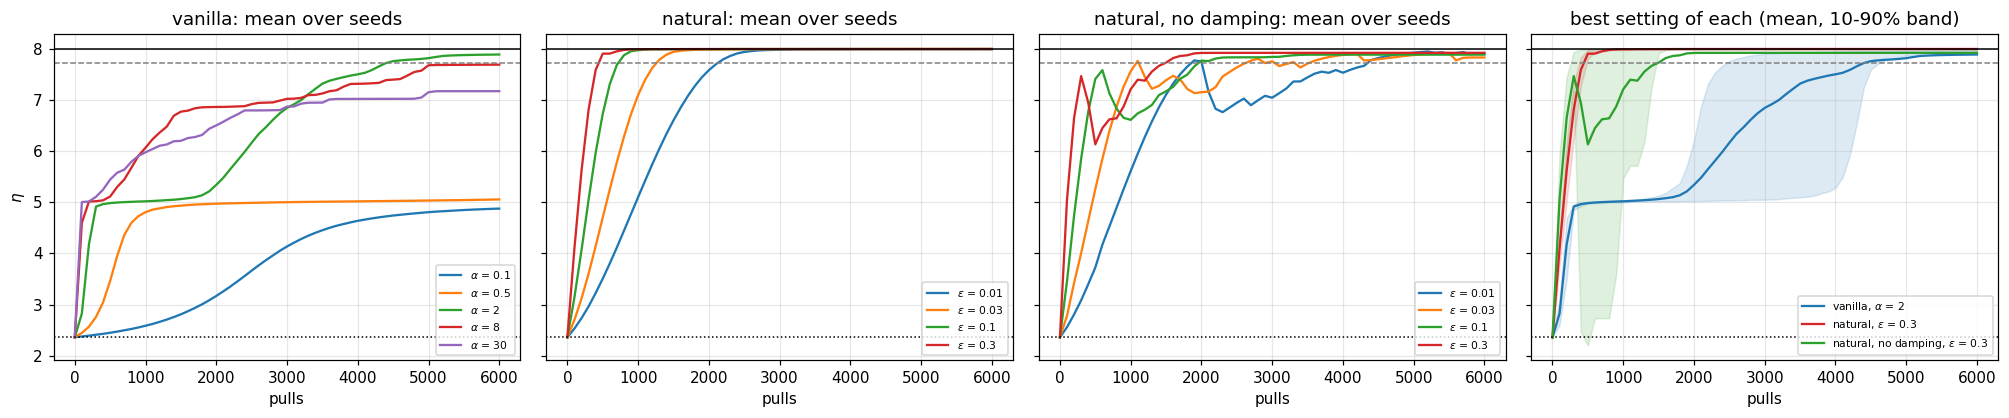

best setting of each method by mean final return: {'vanilla': 'lr=2', 'natural': 'eps=0.3', 'natural, no damping': 'eps=0.3'}


In [9]:
def band(ax, C, label, **kw):
    x = np.arange(C.shape[1]) * BATCH_SIZE
    mean = C.mean(0); lo, hi = np.percentile(C, [10, 90], axis=0)
    line, = ax.plot(x, mean, label=label, **kw); ax.fill_between(x, lo, hi, alpha=0.15, color=line.get_color())

labels = ["vanilla", "natural"] + (["natural, no damping"] if INCLUDE_UNDAMPED else [])
best = {lab: max((k for k in sampled if k[0] == lab), key=lambda k: sampled[k][0][:, -1].mean()) for lab in labels}
fig, axes = plt.subplots(1, len(labels) + 1, figsize=(4.6 * (len(labels) + 1), 3.9), sharey=True)
for ax, lab in zip(axes[:-1], labels):
    for k, (C, _) in sampled.items():
        if k[0] == lab:
            ax.plot(np.arange(C.shape[1]) * BATCH_SIZE, C.mean(0), label=f"{hp_label(lab)} = {k[1]:g}")
    ax.set_title(f"{lab}: mean over seeds"); ax.legend(fontsize=7, loc="lower right")
for lab, col in zip(labels, ["C0", "C3", "C2"]):
    k = best[lab]; band(axes[-1], sampled[k][0], f"{lab}, {hp_label(lab)} = {k[1]:g}", color=col)
axes[-1].set_title("best setting of each (mean, 10-90% band)")
for ax in axes:
    ax.axhline(ETA_STAR, color="k", lw=1); ax.axhline(ETA_INIT, color="k", lw=1, ls=":"); ax.axhline(TARGET, color="gray", lw=1, ls="--")
    ax.set_xlabel("pulls")
axes[-1].legend(fontsize=7, loc="lower right"); axes[0].set_ylabel(r"$\eta$"); plt.tight_layout(); plt.show()
print("best setting of each method by mean final return:", {lab: f"{('lr' if lab == 'vanilla' else 'eps')}={k[1]:g}" for lab, k in best.items()})

**Reading the results.** Compare, at equal batch size, how many pulls each method needs and how often it ends on the best arm; compare also how wide the range of good settings is for each method.
With a well-chosen learning rate, vanilla ascent can be as fast as natural gradient on easy configurations, but its numbers depend on the chart (`REF_ARM`): see Experiment E. What to look for is the *sensitivity* to the setting (Experiment D) and the behaviour on
the configurations where the best arm starts with a small probability (`INIT_MODE`) or where there are many arms (`ARMS_MODE = "random"` with a large `N_ARMS`).

### The failure mode without damping

If an arm with a small but non-negligible probability gets no sample in a batch, $\hat F$ contains almost no information about the coordinate $\theta_a$ of that arm,
and solving the regression divides noise by about $\pi_a$ (the exact Fisher entry $F_{aa}=\pi_a(1-\pi_a)$ is small). The fitted $w$ then becomes huge in that coordinate. Moreover the step size $\alpha$
is computed from $\hat F$, which only sees the sampled arms, so the KL budget cannot see that the step moves the unsampled arm by a large amount.
The trace below follows the worst undamped run (at the middle setting of `EPS_GRID`), around the iteration where $\eta$ drops the most: watch the column of unsampled arms next to $\max|w|$.

In [10]:
if INCLUDE_UNDAMPED:
    eps_demo = EPS_GRID[len(EPS_GRID) // 2]
    C_und = sampled[("natural, no damping", eps_demo)][0]
    seed_bad = int(np.argmin(C_und[:, -1]))
    curve, _, log = run_sampled("natural", N_ITERS, seed_bad, eps=eps_demo, lam=0.0, trace=True)
    k_drop = int(np.argmin(np.diff(curve))) if np.diff(curve).min() < 0 else 0
    lo = max(0, k_drop - TRACE_ITERS // 2); hi = min(len(log), lo + TRACE_ITERS)
    print(f"undamped natural gradient, eps={eps_demo:g}, worst seed = {seed_bad} (final eta = {curve[-1]:.3f}); largest single drop of eta at iteration {k_drop}")
    print(f"{'k':>3s} {'pi (best arm' + (', all arms' if K <= 6 else '') + ')':>34s} {'unsampled arms':>15s} {'max |w|':>10s} {'alpha':>9s} {'eta':>8s}")
    for k, pi, n_unsampled, wmax, alpha, e in log[lo:hi]:
        pistr = np.array2string(pi, precision=3) if K <= 6 else f"{pi[BEST]:.4f}"
        print(f"{k:3d} {pistr:>34s} {n_unsampled:15d} {wmax:10.3g} {alpha:9.3g} {e:8.3f}")
else:
    print("set INCLUDE_UNDAMPED = True to see the failure trace")

undamped natural gradient, eps=0.1, worst seed = 26 (final eta = 3.583); largest single drop of eta at iteration 7
  k            pi (best arm, all arms)  unsampled arms    max |w|     alpha      eta
  1                [0.641 0.208 0.151]               0        5.6     0.221    3.531
  2                [0.416 0.245 0.339]               0       5.95     0.168    4.770
  3                [0.236 0.241 0.523]               0       5.88     0.175    5.863
  4                [0.11  0.202 0.687]               0       6.96     0.173    6.731
  5                [0.04  0.131 0.829]               0       5.82     0.264    7.367
  6                [0.01  0.06  0.931]               0       9.03      0.42    7.763
  7                [0.    0.018 0.982]               1        178     0.881    7.945
  8                [0.835 0.002 0.163]               1        161     0.164    2.985
  9                [0.011 0.986 0.003]               2          0     0.447    4.977
 10                [0.011 0.986 0.0

## 7. Experiment C: reparametrization test

Use the chart $\psi=D\theta$ with a diagonal matrix $D$ whose entries are drawn log-uniformly from $[1/\text{`CHART\_SCALE\_SPREAD`},\,\text{`CHART\_SCALE\_SPREAD`}]$:
the same policies, written with different units for each coordinate. The theory predicts:

- **vanilla:** the gradient has components $\nabla_\psi\eta=D^{-1}\nabla_\theta\eta$ (a covector) but is added to $\psi$ (a vector), so $\Delta\theta=\text{lr}\,D^{-2}\nabla_\theta\eta$: a different direction in $M$, hence a different trajectory;
- **natural:** $F_\psi=D^{-1}F_\theta D^{-1}$ and $w_\psi=Dw_\theta$, while $\alpha$ depends only on $F(w,w)$, which is chart-independent, so $\Delta\theta=\alpha w_\theta$ in every chart: the same trajectory.
  The damping $\lambda\Lambda$ with $\Lambda=D^{-2}$ is "$\lambda I$ in the chart $\theta$", which keeps this exact (a damping $\lambda I$ in the chart $\psi$ would not).

Since $\psi=D\theta$ is linear, the discrete step is exactly covariant here, not only to first order (Step 15). The sampled runs use the same seed, so the data coincide whenever the policies coincide.

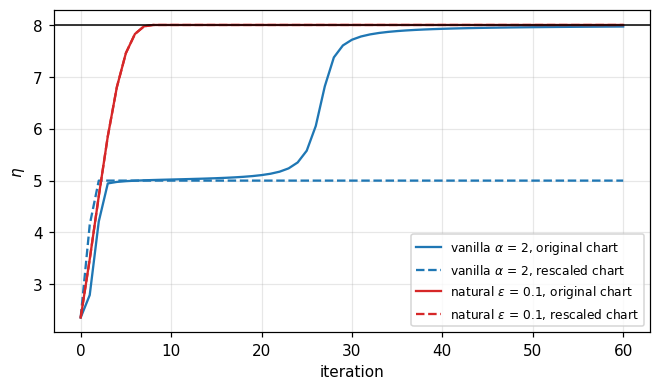

exact gradients:   max |eta(rescaled) - eta(original)|   vanilla = 2.97,  natural = 8.88e-16
sampled gradients: max |eta(rescaled) - eta(original)|   vanilla = 2.92,  natural = 2.22e-15


In [11]:
SCALES = np.exp(np.random.default_rng(123).uniform(-np.log(CHART_SCALE_SPREAD), np.log(CHART_SCALE_SPREAD), N_FREE))
lr_ref, eps_ref = LR_GRID[len(LR_GRID) // 2], EPS_GRID[len(EPS_GRID) // 2]
n_it = min(N_ITERS_EXACT, 60)
curves = {
    f"vanilla {hp_label('lr')} = {lr_ref:g}, original chart":   run_exact("vanilla", n_it, lr=lr_ref),
    f"vanilla {hp_label('lr')} = {lr_ref:g}, rescaled chart":   run_exact("vanilla", n_it, lr=lr_ref, scales=SCALES),
    f"natural {hp_label('eps')} = {eps_ref:g}, original chart": run_exact("natural", n_it, eps=eps_ref),
    f"natural {hp_label('eps')} = {eps_ref:g}, rescaled chart": run_exact("natural", n_it, eps=eps_ref, scales=SCALES),
}
fig, ax = plt.subplots(figsize=(7, 3.8))
for (name, c), ls, col in zip(curves.items(), ["-", "--", "-", "--"], ["C0", "C0", "C3", "C3"]): ax.plot(c, ls=ls, color=col, label=name)
ax.axhline(ETA_STAR, color="k", lw=1); ax.set_xlabel("iteration"); ax.set_ylabel(r"$\eta$"); ax.legend(fontsize=8); plt.show()
k = list(curves.values())
print("exact gradients:   max |eta(rescaled) - eta(original)|   vanilla = %.3g,  natural = %.3g" % (np.abs(k[0] - k[1]).max(), np.abs(k[2] - k[3]).max()))

v1, _ = run_sampled("vanilla", 40, 0, lr=lr_ref);                    v2, _ = run_sampled("vanilla", 40, 0, lr=lr_ref, scales=SCALES)
n1, _ = run_sampled("natural", 40, 0, eps=eps_ref);                  n2, _ = run_sampled("natural", 40, 0, eps=eps_ref, scales=SCALES)
print("sampled gradients: max |eta(rescaled) - eta(original)|   vanilla = %.3g,  natural = %.3g" % (np.abs(v1 - v2).max(), np.abs(n1 - n2).max()))

## 8. Experiment D: sensitivity to the hyperparameter

What does it cost to use the "wrong" parametrization? Take the uniform rescaling $\psi=c\,\theta$ with $c=$ `SENS_CHART_SCALE` and measure the median (over `SENS_SEEDS` runs) of $\eta$ after `SENS_ITERS` updates,
as a function of the learning rate (vanilla) or of the KL budget $\varepsilon$ (natural), in the original chart ($c=1$) and in the rescaled chart.

For vanilla the effective learning rate in the original coordinates is $\text{lr}/c^2$, so the window of good learning rates should shift by a factor $c^2$.
For natural gradient the curve should not move at all: the good range of $\varepsilon$ is a property of the problem, not of the parametrization. The grids are set by `SENS_LR_LOG10`, `SENS_EPS_LOG10`, `SENS_POINTS`.

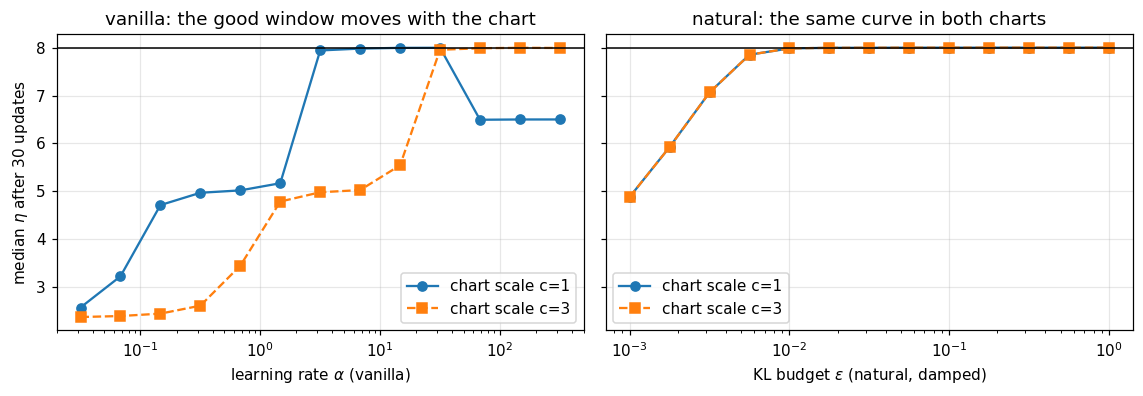

natural gradient: max |curve(c=3) - curve(c=1)| = 3.55e-15


In [12]:
def eta_after(n_iter, seeds, **kw):
    return float(np.median([run_sampled(n_iter=n_iter, seed=s, **kw)[0][-1] for s in seeds]))

lrs  = np.logspace(SENS_LR_LOG10[0],  SENS_LR_LOG10[1],  SENS_POINTS)
epss = np.logspace(SENS_EPS_LOG10[0], SENS_EPS_LOG10[1], SENS_POINTS)
seeds = range(SENS_SEEDS)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7), sharey=True)
sens = {}
for c, style in [(1.0, "o-"), (SENS_CHART_SCALE, "s--")]:
    sc = np.full(N_FREE, c)
    sens[("vanilla", c)] = [eta_after(SENS_ITERS, seeds, method="vanilla", lr=lr, scales=sc) for lr in lrs]
    sens[("natural", c)] = [eta_after(SENS_ITERS, seeds, method="natural", eps=e, scales=sc) for e in epss]
    axes[0].semilogx(lrs,  sens[("vanilla", c)], style, label=f"chart scale c={c:g}")
    axes[1].semilogx(epss, sens[("natural", c)], style, label=f"chart scale c={c:g}")
axes[0].set_xlabel(r"learning rate $\alpha$ (vanilla)"); axes[1].set_xlabel(r"KL budget $\varepsilon$ (natural, damped)")
axes[0].set_ylabel(fr"median $\eta$ after {SENS_ITERS} updates")
axes[0].set_title("vanilla: the good window moves with the chart"); axes[1].set_title("natural: the same curve in both charts")
for ax in axes: ax.axhline(ETA_STAR, color="k", lw=1); ax.legend()
plt.tight_layout(); plt.show()
print("natural gradient: max |curve(c=%g) - curve(c=1)| = %.3g" % (SENS_CHART_SCALE, np.max(np.abs(np.array(sens[("natural", SENS_CHART_SCALE)]) - np.array(sens[("natural", 1.0)])))))

## 9. Experiment E: vanilla ascent depends on which arm is the reference

All charts $\theta^{(\rm ref)}$ describe the same manifold $M$, and the choice of the reference arm is pure convention. If an algorithm were *intrinsic*, its trajectory would not depend on it.

- **natural gradient:** $\operatorname{grad}_F\eta$ is a vector on $M$, so the exact trajectory is identical for every reference arm, **provided `MAX_LOGIT_STEP` does not bind** (with `MAX_LOGIT_STEP = None` the trajectories agree to round-off). The cap limits the change of the *coordinates*, and switching the reference arm is a non-diagonal change of coordinates, so the cap is not invariant; it is invariant under the diagonal rescalings of Experiment C. The *sampled* version with damping also differs very slightly, because the damping $\lambda I$ refers to the chart $\theta$, which changes with the reference arm.
- **vanilla ascent:** it adds the components of $d\eta$ to the coordinates, which uses the metric "$I$ in the chart". For the reference arm $r$ the chart pins the logit of $r$, so the coordinates that *can* move are those of the other arms,
  and the effective metric on $M$ changes with $r$. Different $r$ give genuinely different algorithms.

The tables show, for several choices of the reference arm (the best and the worst arm are always included), the number of exact iterations to reach `TARGET`, and the number of sampled runs (out of `N_SEEDS`) that reach it.

EXACT gradients: iterations to reach the target eta = 7.718  ('-': not within 100 iterations)
   reference arm   lr=0.1   lr=0.5     lr=2     lr=8    lr=30    natural eps=0.1
   0 (mean 2.00)        -        -        -       48        4                  6
   1 (mean 5.00)       81       17        5        2        2                  6
2 (mean 8.00) best        -        -       31       12       30                  6

SAMPLED: runs (out of 40) that reach the target
   reference arm   lr=0.1   lr=0.5     lr=2     lr=8    lr=30    natural eps=0.1


   0 (mean 2.00)        0        0        3       15       26                 39


   1 (mean 5.00)        0       40       40       40       40                 40


2 (mean 8.00) best        0        0       39       36       29                 40


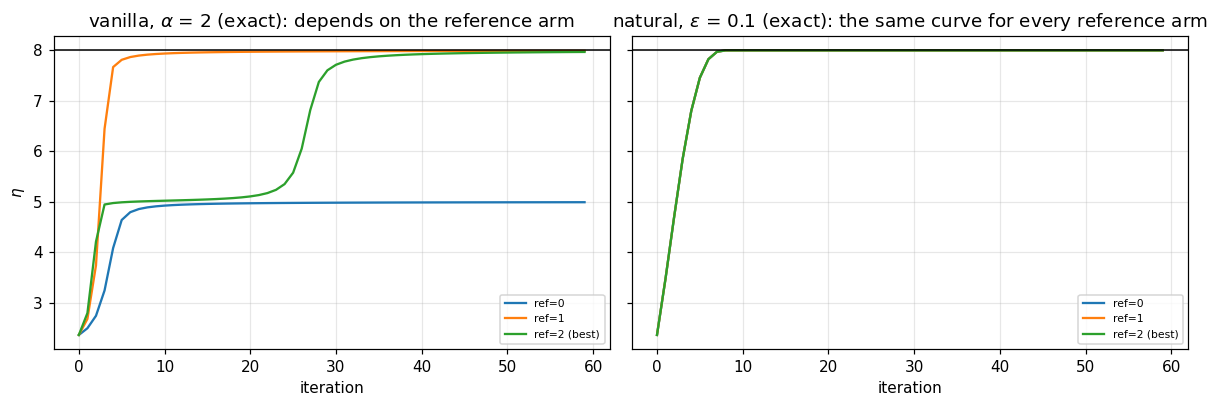

In [13]:
refs = reference_arms()
lr_cols = LR_GRID; eps_ref = EPS_GRID[len(EPS_GRID) // 2]

print(f"EXACT gradients: iterations to reach the target eta = {TARGET:.3f}  ('-': not within {N_ITERS_EXACT} iterations)")
print(f"{'reference arm':>16s} " + " ".join(f"{'lr=' + format(lr, 'g'):>8s}" for lr in lr_cols) + f" {'natural eps=' + format(eps_ref, 'g'):>18s}")
curves_E = {}
for ref in refs:
    with with_reference(ref):
        row = []
        for lr in lr_cols:
            c = run_exact("vanilla", N_ITERS_EXACT, lr=lr); row.append(first_hit(c, TARGET))
            if lr == LR_GRID[len(LR_GRID) // 2]: curves_E[(ref, "vanilla")] = c
        cn = run_exact("natural", N_ITERS_EXACT, eps=eps_ref); curves_E[(ref, "natural")] = cn
        tag = f"{ref} (mean {MEANS[ref]:.2f})" + (" best" if ref == BEST else "")
        print(f"{tag:>16s} " + " ".join(f"{('-' if h is None else h):>8}" for h in row) + f" {str(first_hit(cn, TARGET)):>18s}")

print(f"\nSAMPLED: runs (out of {N_SEEDS}) that reach the target")
print(f"{'reference arm':>16s} " + " ".join(f"{'lr=' + format(lr, 'g'):>8s}" for lr in lr_cols) + f" {'natural eps=' + format(eps_ref, 'g'):>18s}")
for ref in refs:
    with with_reference(ref):
        row = []
        for lr in lr_cols:
            C, _ = many_sampled("vanilla", lr=lr); row.append(sum(first_hit(c, TARGET) is not None for c in C))
        Cn, _ = many_sampled("natural", eps=eps_ref)
        tag = f"{ref} (mean {MEANS[ref]:.2f})" + (" best" if ref == BEST else "")
        print(f"{tag:>16s} " + " ".join(f"{h:>8d}" for h in row) + f" {sum(first_hit(c, TARGET) is not None for c in Cn):>18d}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ref in refs:
    lab = f"ref={ref}" + (" (best)" if ref == BEST else "")
    axes[0].plot(curves_E[(ref, "vanilla")][:60], label=lab); axes[1].plot(curves_E[(ref, "natural")][:60], label=lab)
axes[0].set_title(f"vanilla, {hp_label('lr')} = {LR_GRID[len(LR_GRID) // 2]:g} (exact): depends on the reference arm")
axes[1].set_title(f"natural, {hp_label('eps')} = {eps_ref:g} (exact): the same curve for every reference arm")
for ax in axes: ax.axhline(ETA_STAR, color="k", lw=1); ax.set_xlabel("iteration"); ax.legend(fontsize=7, loc="lower right")
axes[0].set_ylabel(r"$\eta$"); plt.tight_layout(); plt.show()

## 10. Things to change (all in the configuration cell)

- **Arms:** `ARMS_MODE = "random"` with `N_ARMS`, `MEAN_RANGE`, `MEANS_SEED` (try a large `N_ARMS`, and raise `BATCH_SIZE` well above the number of arms so that $\hat F$ is informative); or edit `MEANS_MANUAL`.
- **Noise:** `REWARD_VARIANCE` (a list gives each arm its own variance), `BATCH_SIZE`, `BASELINE`.
- **Starting point:** `INIT_MODE = "best_arm_prob"` with `BEST_ARM_INIT_PROB` (the plateau case: the best arm is rarely played), `"uniform"`, or `"manual"` with `INIT_PROBS`.
- **The chart:** `REF_ARM` (which arm's logit is pinned to 0), and `N_REF_TESTED` for Experiment E. The natural direction changes components, $\mu_b-\mu_{\rm ref}$, but it is the same vector on $M$: the exact trajectories of natural gradient do not depend on this choice, those of vanilla ascent do.
- **Regularisation:** `DAMPING` / `DAMPING_SCALE` (try `0` to reproduce the failure mode everywhere), `MAX_LOGIT_STEP` (`None` switches the cap off).
- **Experiments:** `LR_GRID`, `EPS_GRID`, `N_ITERS`, `N_SEEDS`, `SUCCESS_FRAC`, and the sensitivity-test ranges.